# 05 — Redes recurrentes: LSTM y DRNN (familia A: dominio del tiempo)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/05_recurrentes_lstm.ipynb)

**Entrega 2 — Notebook 5 de 7.** Segunda arquitectura en el dominio del tiempo: redes **recurrentes** con
celdas LSTM, que procesan la ventana paso a paso y mantienen un estado interno. Es la familia del
artículo de referencia (Murad & Pyun, 2017), cuyo mejor resultado sobre este dataset es una **DRNN
unidireccional de 4 capas con 96.7 %**.

**Experimentos (iteraciones):**

| Id | Arquitectura | Idea |
|---|---|---|
| R1 | LSTM de 2 capas (64 unidades) | recurrente mínima |
| R2 | DRNN: LSTM de 4 capas, clasifica con el **último paso** | primera versión de la DRNN |
| R3 | BiLSTM de 2 capas (64 unidades) | leer la ventana en ambos sentidos |
| R4 | CNN-LSTM: 2 × Conv1D + MaxPool(2) → LSTM(64) | la convolución resume y acorta la secuencia (64 pasos) |
| **R5** | DRNN: LSTM de 4 capas, **promedia las salidas de todos los pasos** (Ec. 9 del artículo) | **versión final de la DRNN, fiel al artículo** |

**Entrada:** los 9 canales crudos, como en el artículo (sin magnitudes ni velocidad: en el notebook 04 no
aportaron una mejora distinguible del ruido). **Protocolo** idéntico al notebook 04: validación por sujeto
dentro del train, normalizador ajustado solo con entrenamiento, test oficial al final, y media ± desviación
sobre varias semillas (aquí (42, 43), por el costo de entrenar redes recurrentes en CPU).

La **sección 5** responde por qué nuestra DRNN no llega al 96.7 % publicado: se reproduce el protocolo del
artículo y se mide cuánto aporta cada diferencia.

> **Tiempo de ejecución.** Las LSTM son lentas en CPU (≈ 55 min en total). En Colab, activa una **GPU**
> (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*) para que el notebook tarde mucho menos.

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: C:\Users\GARCIA\Documents\HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


C:\Users\GARCIA\Documents\HAR\.venv\Scripts\python.exe: No module named pip


In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

WindowsPath('C:/Users/GARCIA/Documents/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

from data_loader import load_all_raw, load_raw_signals
from evaluation import plot_confusion_matrix, plot_history
from preprocessing import CLASS_NAMES, ChannelStandardizer, encode_labels
from training import evaluate_keras, fit_keras, prepare_time_inputs

pd.set_option("display.width", 130)
SEEDS = (42, 43)
MAX_EPOCHS = 30

X_tr_raw, y_tr_s, s_tr = load_raw_signals("train")
X_te_raw, y_te_s, _ = load_raw_signals("test")
y_tr, y_te = encode_labels(y_tr_s), encode_labels(y_te_s)
s_tr = s_tr.values

d = prepare_time_inputs(X_tr_raw, X_te_raw, s_tr, "raw")       # 9 canales, partición por sujeto
ytr, yva = y_tr[d["tr"]], y_tr[d["va"]]
print("entrenamiento:", d["Xtr"].shape, "| validación:", d["Xva"].shape, "| test:", d["Xte"].shape,
      "| GPU:", bool(tf.config.list_physical_devices("GPU")))

entrenamiento: (5551, 128, 9) | validación: (1801, 128, 9) | test: (2947, 128, 9) | GPU: False


## 1. Arquitecturas

Una LSTM lee la ventana de 128 pasos en orden; en cada paso decide qué recordar y qué olvidar. Las capas
intermedias devuelven la secuencia completa (`return_sequences=True`) para que la siguiente capa la procese.

Hay dos formas de convertir la secuencia en una clase:

- **Último paso** (R1–R4): la última capa devuelve solo su estado final, que alimenta al clasificador.
- **Promedio temporal** (R5): como en la Ec. 9 de Murad & Pyun, la última capa produce una puntuación
  `y_t` en **cada** paso y la clase sale de `softmax((1/T) · Σ_t y_t)`. Así cada instante de la ventana
  contribuye a la decisión, no solo el final.

In [5]:
def build_lstm(input_shape, n_layers=2, units=64, bidirectional=False, mean_over_time=False, name="lstm"):
    inp = keras.Input(input_shape)
    x = inp
    for k in range(n_layers):
        devolver_secuencia = (k < n_layers - 1) or mean_over_time
        capa = layers.LSTM(units, return_sequences=devolver_secuencia)
        x = layers.Bidirectional(capa)(x) if bidirectional else capa(x)
        x = layers.Dropout(0.3)(x)
    if mean_over_time:                                  # Ec. 9 del artículo
        x = layers.Dense(6)(x)                          # puntuación y_t en cada paso
        x = layers.GlobalAveragePooling1D()(x)          # (1/T) Σ_t y_t
        return keras.Model(inp, layers.Softmax()(x), name=name)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


def build_cnn_lstm(input_shape, units=64, name="cnn_lstm"):
    inp = keras.Input(input_shape)
    x = inp
    for _ in range(2):
        x = layers.Conv1D(64, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling1D(2)(x)                      # 128 -> 64 pasos
    x = layers.Dropout(0.3)(x)
    x = layers.LSTM(units)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation="softmax")(x), name=name)


ARQUITECTURAS = {
    "R1": ("LSTM 2 capas", lambda s: build_lstm(s, 2, name="r1_lstm2")),
    "R2": ("DRNN 4 capas, último paso", lambda s: build_lstm(s, 4, name="r2_drnn4")),
    "R3": ("BiLSTM 2 capas", lambda s: build_lstm(s, 2, bidirectional=True, name="r3_bilstm2")),
    "R4": ("CNN-LSTM", lambda s: build_cnn_lstm(s, name="r4_cnn_lstm")),
    "R5": ("DRNN 4 capas, promedio temporal", lambda s: build_lstm(s, 4, mean_over_time=True, name="r5_drnn4_prom")),
}
for k, (nombre, f) in ARQUITECTURAS.items():
    print(f"{k} {nombre:32s} parámetros: {f(d['Xtr'].shape[1:]).count_params():,}")

R1 LSTM 2 capas                     parámetros: 56,518


R2 DRNN 4 capas, último paso        parámetros: 122,566
R3 BiLSTM 2 capas                   parámetros: 145,350
R4 CNN-LSTM                         parámetros: 61,574


R5 DRNN 4 capas, promedio temporal  parámetros: 118,406

## 2. Entrenamiento

Mismo procedimiento que en el notebook 04: Adam (lr = 1e-3), `EarlyStopping` sobre la pérdida de
validación (paciencia 8, restaura los mejores pesos) y `ReduceLROnPlateau`.

In [6]:
runs, histories = {}, {}
t_total = time.perf_counter()

for exp, (nombre, build) in ARQUITECTURAS.items():
    runs[exp] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = build(d["Xtr"].shape[1:])
        hist, seg = fit_keras(model, d["Xtr"], ytr, d["Xva"], yva, epochs=MAX_EPOCHS)
        mejor = int(np.argmin(hist.history["val_loss"]))
        res = evaluate_keras(f"05_{exp}_s{seed}", "tiempo_recurrente", model, d["Xte"], y_te, CLASS_NAMES, seg,
                             notes=f"{exp}: {nombre}, semilla={seed}")
        res.update(val_loss=hist.history["val_loss"][mejor], val_acc=hist.history["val_accuracy"][mejor],
                   epocas=len(hist.history["loss"]))
        runs[exp].append(res)
        if seed == SEEDS[0]:
            histories[exp] = hist
    print(f"{exp} listo ({(time.perf_counter() - t_total) / 60:.1f} min acumulados)")

[05_R1_s42] accuracy=0.8962  F1 macro=0.8956  latencia=6.57 ms/ventana


[05_R1_s43] accuracy=0.9026  F1 macro=0.9011  latencia=6.62 ms/ventana
R1 listo (3.6 min acumulados)


[05_R2_s42] accuracy=0.8897  F1 macro=0.8847  latencia=24.03 ms/ventana


[05_R2_s43] accuracy=0.8880  F1 macro=0.8881  latencia=12.62 ms/ventana
R2 listo (13.8 min acumulados)


[05_R3_s42] accuracy=0.8836  F1 macro=0.8834  latencia=9.97 ms/ventana


[05_R3_s43] accuracy=0.9091  F1 macro=0.9093  latencia=9.91 ms/ventana
R3 listo (18.6 min acumulados)


[05_R4_s42] accuracy=0.9169  F1 macro=0.9170  latencia=2.18 ms/ventana


[05_R4_s43] accuracy=0.9253  F1 macro=0.9262  latencia=2.10 ms/ventana
R4 listo (20.1 min acumulados)


[05_R5_s42] accuracy=0.9175  F1 macro=0.9175  latencia=11.97 ms/ventana


[05_R5_s43] accuracy=0.8938  F1 macro=0.8929  latencia=11.94 ms/ventana
R5 listo (27.6 min acumulados)


## 3. Resultados por experimento

,arquitectura,val acc,test acc,F1 macro test,parámetros,latencia (ms/ventana),tamaño (KB),épocas (media),entrenamiento (s)
R1,LSTM 2 capas,0.9725 ± 0.0081,0.8994 ± 0.0032,0.8983 ± 0.0028,56518,6.6,221.0,16.0,103.0
R2,"DRNN 4 capas, último paso",0.9631 ± 0.0108,0.8889 ± 0.0008,0.8864 ± 0.0017,122566,18.323,479.0,13.0,289.0
R3,BiLSTM 2 capas,0.9864 ± 0.0008,0.8963 ± 0.0127,0.8964 ± 0.0130,145350,9.937,568.0,12.5,133.4
R4,CNN-LSTM,0.9800 ± 0.0044,0.9211 ± 0.0042,0.9216 ± 0.0046,61574,2.14,241.0,15.0,44.3
R5,"DRNN 4 capas, promedio temporal",0.9767 ± 0.0044,0.9057 ± 0.0119,0.9052 ± 0.0123,118406,11.953,463.0,15.0,214.3


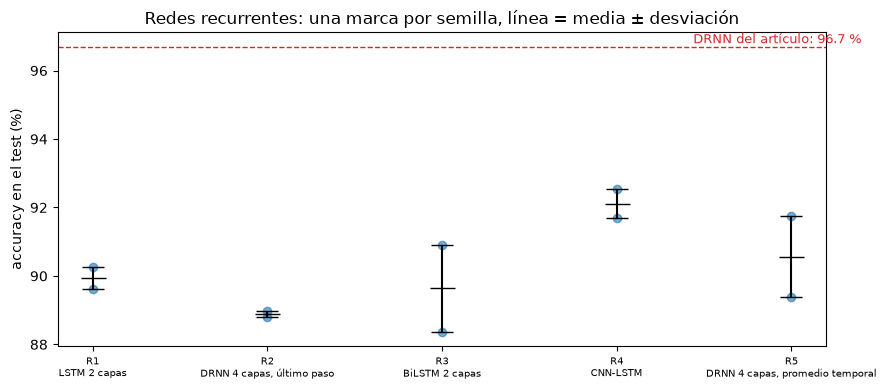

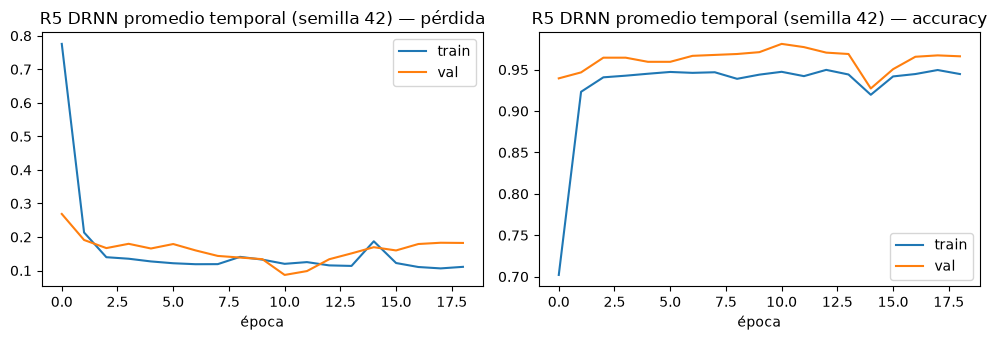

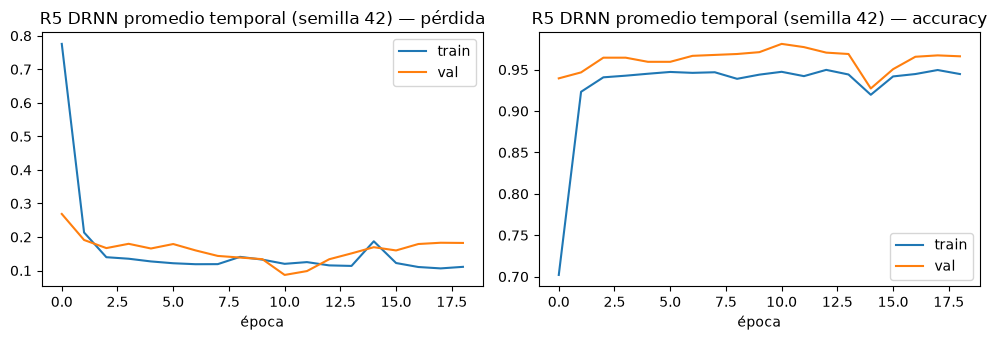

In [7]:
def ms(exp, clave):
    v = np.array([r[clave] for r in runs[exp]], dtype=float)
    return v.mean(), v.std()


filas = {}
for exp, (nombre, _) in ARQUITECTURAS.items():
    fila = {"arquitectura": nombre}
    for etiqueta, clave in [("val acc", "val_acc"), ("test acc", "accuracy"), ("F1 macro test", "f1_macro")]:
        m, s = ms(exp, clave)
        fila[etiqueta] = f"{m:.4f} ± {s:.4f}"
    fila["parámetros"] = runs[exp][0]["n_params"]
    fila["latencia (ms/ventana)"] = round(ms(exp, "latency_single_ms")[0], 3)
    fila["tamaño (KB)"] = round(runs[exp][0]["model_size_kb"], 0)
    fila["épocas (media)"] = round(ms(exp, "epocas")[0], 1)
    fila["entrenamiento (s)"] = round(ms(exp, "train_time_s")[0], 1)
    filas[exp] = fila
display(pd.DataFrame(filas).T)

fig, ax = plt.subplots(figsize=(9, 4))
for k, exp in enumerate(ARQUITECTURAS):
    accs = [100 * r["accuracy"] for r in runs[exp]]
    ax.scatter([k] * len(accs), accs, color="C0", alpha=0.6, zorder=3)
    ax.errorbar(k, np.mean(accs), yerr=np.std(accs), fmt="_", color="k", capsize=8, markersize=18, zorder=4)
ax.axhline(96.7, color="C3", ls="--", lw=1)
ax.text(len(ARQUITECTURAS) - 0.6, 96.8, "DRNN del artículo: 96.7 %", color="C3", ha="right", fontsize=9)
ax.set_xticks(range(len(ARQUITECTURAS)), [f"{e}\n{ARQUITECTURAS[e][0]}" for e in ARQUITECTURAS], fontsize=7)
ax.set_ylabel("accuracy en el test (%)")
ax.set_title("Redes recurrentes: una marca por semilla, línea = media ± desviación")
fig.tight_layout()
plt.show()

plot_history(histories["R5"], title="R5 DRNN promedio temporal (semilla 42)", save_name="05_curvas_R5.png")

## 4. Finalista de la familia y errores por clase

Se elige por la **menor pérdida de validación media** (no por el test).

Pérdida de validación media: {'R1': np.float64(0.1146), 'R2': np.float64(0.1161), 'R3': np.float64(0.0911), 'R4': np.float64(0.0784), 'R5': np.float64(0.098)}
Finalista recurrente: R4 (CNN-LSTM), pérdida de validación media = 0.0784


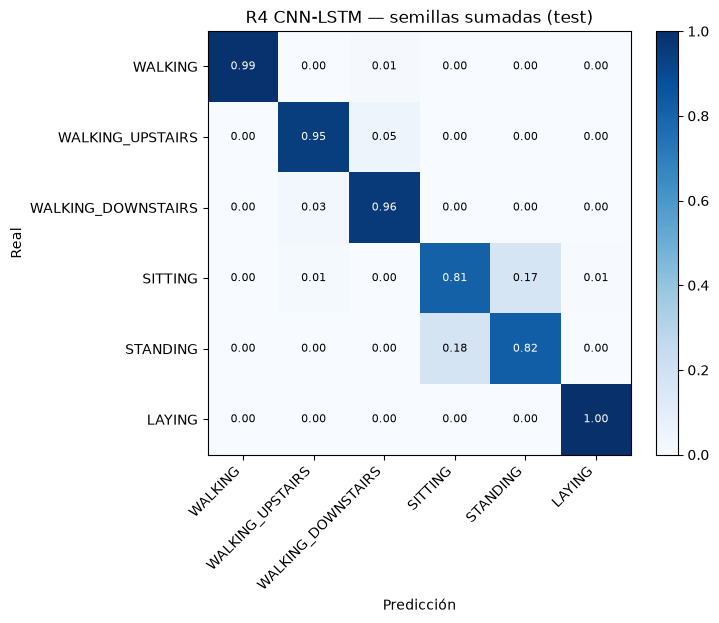

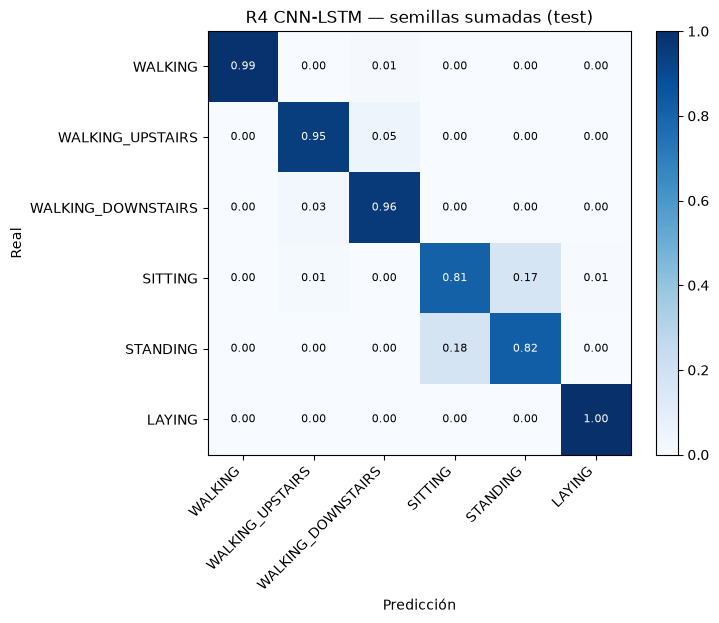

In [8]:
finalista = min(ARQUITECTURAS, key=lambda e: ms(e, "val_loss")[0])
print("Pérdida de validación media:", {e: round(ms(e, "val_loss")[0], 4) for e in ARQUITECTURAS})
print(f"Finalista recurrente: {finalista} ({ARQUITECTURAS[finalista][0]}), "
      f"pérdida de validación media = {ms(finalista, 'val_loss')[0]:.4f}")

cm = np.sum([r["confusion_matrix"] for r in runs[finalista]], axis=0)
plot_confusion_matrix(cm, CLASS_NAMES, title=f"{finalista} {ARQUITECTURAS[finalista][0]} — semillas sumadas (test)",
                      save_name="05_confusion_finalista.png")

## 5. ¿Por qué el artículo reporta 96.7 % y nuestra DRNN no?

Al revisar Murad & Pyun (2017) encontramos estas diferencias con nuestro protocolo:

| | Artículo (UCI-HAD) | Este proyecto |
|---|---|---|
| Partición | "80 % de los datos para entrenar y 20 % para probar" (11,988 / 2,997 ejemplos); no menciona la partición oficial por sujeto | partición oficial por sujeto (21 / 9) |
| Validación | no se describe un conjunto de validación | 5 sujetos de validación para la parada temprana |
| Salida de la red | promedio de las salidas de todos los pasos (Ec. 9) | R2: último paso · R5: promedio (como el artículo) |
| Hiperparámetros | unidades, lr, lote, épocas y dropout no reportados ("ajustados durante el entrenamiento") | fijos, sin búsqueda |
| Preprocesado | señales crudas, sin normalizar | estandarización por canal |

El número de ejemplos del artículo (14,985 en total) es mayor que las 10,299 ventanas oficiales, así que
re-segmentaron las señales. Con una partición aleatoria, las ventanas traslapadas de un mismo sujeto caen a
ambos lados (la fuga medida en el notebook 02).

**Experimento.** Partimos de la DRNN de 4 capas y cambiamos un factor a la vez (una semilla, 42). Se
registra la accuracy de test **en cada época**: la columna "máx." es lo que se obtendría si se eligiera la
mejor época mirando el test, algo posible cuando no hay conjunto de validación.

| Id | Partición y entrenamiento | Salida |
|---|---|---|
| R2 / R5 | por sujeto, 16 sujetos + 5 de validación, parada temprana (secciones 2–3) | último paso / promedio |
| P1 | por sujeto, los 21 sujetos, 40 épocas sin parada temprana | último paso |
| P2 | **aleatoria 80/20 de ventanas** (los 30 sujetos a ambos lados), 30 épocas | último paso |
| P3 | **aleatoria 80/20 de ventanas**, 30 épocas | promedio (protocolo del artículo) |

In [9]:
class TestPorEpoca(keras.callbacks.Callback):
    """Registra la accuracy de test al final de cada época (solo para diagnóstico, no para elegir modelos)."""

    def __init__(self, X, y):
        super().__init__()
        self.X, self.y, self.acc = X, y, []

    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(self.X, verbose=0, batch_size=512).argmax(1)
        self.acc.append(float((p == self.y).mean()))


def protocolo(nombre, Xtr, ytr_, Xte, yte_, epochs, mean_over_time):
    keras.utils.set_random_seed(42)
    m = build_lstm(Xtr.shape[1:], 4, mean_over_time=mean_over_time, name=nombre)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = TestPorEpoca(Xte, yte_)
    t0 = time.perf_counter()
    m.fit(Xtr, ytr_, epochs=epochs, batch_size=64, callbacks=[cb], verbose=0)
    final = float((m.predict(Xte, verbose=0, batch_size=512).argmax(1) == yte_).mean())
    print(f"{nombre}: final = {final:.4f} | máx. por época = {max(cb.acc):.4f} (época {int(np.argmax(cb.acc)) + 1}) "
          f"| {(time.perf_counter() - t0) / 60:.1f} min")
    return {"final": final, "max": max(cb.acc), "curva": cb.acc}


diag = {}

# P1: por sujeto, los 21 sujetos de entrenamiento, sin validación ni parada temprana
sc = ChannelStandardizer().fit(X_tr_raw)
diag["P1"] = protocolo("P1", sc.transform(X_tr_raw), y_tr, sc.transform(X_te_raw), y_te, 40, False)

# P2 y P3: partición aleatoria 80/20 de las 10,299 ventanas, como en el artículo
X_all, y_all_s, s_all = load_all_raw()
y_all = encode_labels(y_all_s)
i_tr, i_te = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=42)
print("Sujetos presentes a la vez en train y test (partición aleatoria):",
      len(set(s_all.values[i_tr]) & set(s_all.values[i_te])), "de 30")
sc = ChannelStandardizer().fit(X_all[i_tr])
Xa_tr, Xa_te = sc.transform(X_all[i_tr]), sc.transform(X_all[i_te])
diag["P2"] = protocolo("P2", Xa_tr, y_all[i_tr], Xa_te, y_all[i_te], 30, False)
diag["P3"] = protocolo("P3", Xa_tr, y_all[i_tr], Xa_te, y_all[i_te], 30, True)

P1: final = 0.9152 | máx. por época = 0.9284 (época 33) | 11.5 min


Sujetos presentes a la vez en train y test (partición aleatoria): 30 de 30


P2: final = 0.9471 | máx. por época = 0.9544 (época 20) | 9.5 min


P3: final = 0.9568 | máx. por época = 0.9568 (época 18) | 9.4 min


,partición,salida,test (%),máx. por época (%)
Id,,,,
R2,por sujeto (16 + 5 val.),último paso,88.9 ± 0.1,—
R5,por sujeto (16 + 5 val.),promedio,90.6 ± 1.2,—
P1,"por sujeto (21, sin val.)",último paso,91.5,92.8
P2,aleatoria 80/20,último paso,94.7,95.4
P3,aleatoria 80/20,promedio,95.7,95.7
Artículo,80/20 de los datos,promedio,96.7,—


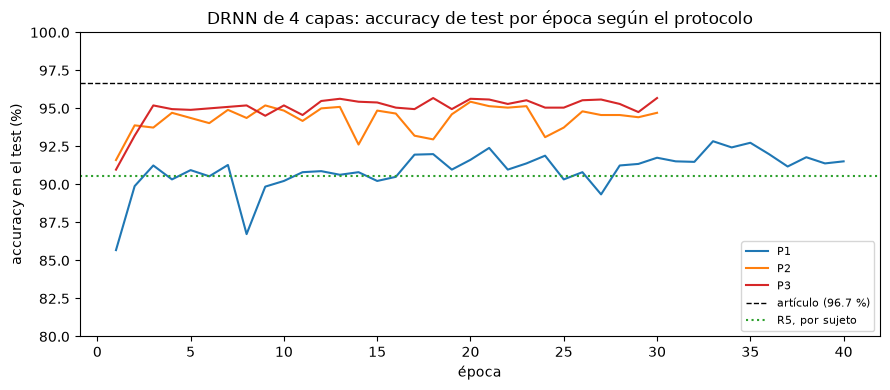

In [10]:
tabla_diag = pd.DataFrame([
    {"Id": "R2", "partición": "por sujeto (16 + 5 val.)", "salida": "último paso",
     "test (%)": f"{100 * ms('R2', 'accuracy')[0]:.1f} ± {100 * ms('R2', 'accuracy')[1]:.1f}", "máx. por época (%)": "—"},
    {"Id": "R5", "partición": "por sujeto (16 + 5 val.)", "salida": "promedio",
     "test (%)": f"{100 * ms('R5', 'accuracy')[0]:.1f} ± {100 * ms('R5', 'accuracy')[1]:.1f}", "máx. por época (%)": "—"},
    {"Id": "P1", "partición": "por sujeto (21, sin val.)", "salida": "último paso",
     "test (%)": f"{100 * diag['P1']['final']:.1f}", "máx. por época (%)": f"{100 * diag['P1']['max']:.1f}"},
    {"Id": "P2", "partición": "aleatoria 80/20", "salida": "último paso",
     "test (%)": f"{100 * diag['P2']['final']:.1f}", "máx. por época (%)": f"{100 * diag['P2']['max']:.1f}"},
    {"Id": "P3", "partición": "aleatoria 80/20", "salida": "promedio",
     "test (%)": f"{100 * diag['P3']['final']:.1f}", "máx. por época (%)": f"{100 * diag['P3']['max']:.1f}"},
    {"Id": "Artículo", "partición": "80/20 de los datos", "salida": "promedio", "test (%)": "96.7", "máx. por época (%)": "—"},
]).set_index("Id")
display(tabla_diag)

fig, ax = plt.subplots(figsize=(9, 4))
for k, col in zip(("P1", "P2", "P3"), ("C0", "C1", "C3")):
    ax.plot(np.arange(1, len(diag[k]["curva"]) + 1), 100 * np.array(diag[k]["curva"]), color=col, label=k)
ax.axhline(96.7, color="k", ls="--", lw=1, label="artículo (96.7 %)")
ax.axhline(100 * ms("R5", "accuracy")[0], color="C2", ls=":", lw=1.5, label="R5, por sujeto")
ax.set_xlabel("época")
ax.set_ylabel("accuracy en el test (%)")
ax.set_ylim(80, 100)
ax.set_title("DRNN de 4 capas: accuracy de test por época según el protocolo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Lectura del diagnóstico.**

- **El factor principal es la partición.** Con la partición aleatoria de ventanas (P2, P3) los 30 sujetos
  aparecen en entrenamiento y en prueba, y ventanas casi idénticas del mismo sujeto caen a ambos lados. La
  accuracy sube varios puntos respecto a la partición por sujeto, en línea con la fuga medida en el notebook 02.
- **La salida promediada (Ec. 9) también ayuda:** R5 mejora a R2 con la misma partición por sujeto, y P3 a P2
  con la partición aleatoria.
- **Más datos y épocas, y elegir la época con el test, suman algo más** (P1 y la columna "máx.").
- **Con el protocolo del artículo (P3), la misma red queda cerca del 96.7 % publicado.** El resto es compatible
  con hiperparámetros no reportados, la re-segmentación de las ventanas y la variación entre semillas.
- **Conclusión:** el 96.7 % no es comparable con una evaluación independiente del sujeto. Con validación por
  sujeto, la DRNN fiel al artículo (R5) es la versión final de la DRNN de este proyecto y rinde al nivel de las
  demás redes, por debajo del SVM sobre las 561 features (notebook 03).

## Conclusiones

In [11]:
mejor_test = max(ARQUITECTURAS, key=lambda e: ms(e, "accuracy")[0])
print(f"- Finalista de la familia recurrente (menor pérdida de validación): {finalista} ({ARQUITECTURAS[finalista][0]}).")
print(f"- Mejor accuracy media en test: {mejor_test} ({ARQUITECTURAS[mejor_test][0]}) = {100 * ms(mejor_test, 'accuracy')[0]:.2f} %.")
print(f"- DRNN de 4 capas: R2 (último paso) {100 * ms('R2', 'accuracy')[0]:.2f} % → R5 (promedio temporal, versión final) "
      f"{100 * ms('R5', 'accuracy')[0]:.2f} %, con partición por sujeto.")
print(f"- Con el protocolo del artículo (partición aleatoria + promedio), la misma red llega a {100 * diag['P3']['final']:.2f} % "
      "(artículo: 96.7 %).")
lat = {e: ms(e, "latency_single_ms")[0] for e in ARQUITECTURAS}
print("- Latencia (ms/ventana, un hilo): " + ", ".join(f"{e} = {v:.2f}" for e, v in lat.items()))
conf = np.array(cm)
i, j = CLASS_NAMES.index("SITTING"), CLASS_NAMES.index("STANDING")
print(f"- En el finalista, SITTING↔STANDING = {100 * (conf[i, j] + conf[j, i]) / (conf.sum() - np.trace(conf)):.0f} % de los errores.")

- Finalista de la familia recurrente (menor pérdida de validación): R4 (CNN-LSTM).
- Mejor accuracy media en test: R4 (CNN-LSTM) = 92.11 %.
- DRNN de 4 capas: R2 (último paso) 88.89 % → R5 (promedio temporal, versión final) 90.57 %, con partición por sujeto.
- Con el protocolo del artículo (partición aleatoria + promedio), la misma red llega a 95.68 % (artículo: 96.7 %).
- Latencia (ms/ventana, un hilo): R1 = 6.60, R2 = 18.32, R3 = 9.94, R4 = 2.14, R5 = 11.95
- En el finalista, SITTING↔STANDING = 77 % de los errores.


**Lectura de los resultados.**

- **R4 (CNN-LSTM) es la recurrente más precisa y rápida.** Las dos convoluciones iniciales resumen la señal y
  acortan la secuencia a 64 pasos.
- **Las LSTM "puras" con salida en el último paso (R1–R3) quedan en torno al 89–90 %;** añadir capas (R2) o
  bidireccionalidad (R3) no ayuda y aumenta parámetros y latencia.
- **La DRNN fiel al artículo (R5)** mejora a R2 (≈ 1.7 puntos en promedio, con más variación entre semillas); su brecha con el 96.7 % publicado se explica en la
  sección 5: sobre todo por la partición aleatoria de ventanas del artículo.
- **Generalización:** las recurrentes llegan a ≈ 96–99 % en los sujetos de validación y bajan varios puntos en
  los del test: el cuello de botella vuelve a ser el cambio de sujeto.

Siguiente: [`06_cnn2d_tiempo_frecuencia.ipynb`](06_cnn2d_tiempo_frecuencia.ipynb) — la segunda familia:
CNN 2D sobre espectrogramas (modalidad tiempo-frecuencia).